In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Connect and Access Git Repository

import os
import sys
from getpass import getpass
from pathlib import Path

GITHUB_USERNAME = "sharaffatima"
REPO_NAME = "bachelor-thesis"



token = getpass("GitHub token: ")


REPO_URL = f"https://{token}@github.com/{GITHUB_USERNAME}/{REPO_NAME}.git"
REPO_DIR = Path("/content") / REPO_NAME


if not REPO_DIR.exists():
    !git clone {REPO_URL} {REPO_DIR}
else:
    %cd {REPO_DIR}
    !git pull

%cd {REPO_DIR}
sys.path.append(str(REPO_DIR))

print("Repo exists:", REPO_DIR.exists())

GitHub token: ··········
/content/bachelor-thesis
Already up to date.
/content/bachelor-thesis
Repo exists: True


In [ ]:
!git pull

Already up to date.


In [ ]:
# Imports
import os
import numpy as np
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve
)

# global configuration

REPO_DIR = Path("/content/bachelor-thesis")
sys.path.append(str(REPO_DIR))


from utils.dataset import PTBXLAnoFormerDataset
from explainability.attention import AnoFormerExplainability
from utils.seed import set_seed, RANDOM_SEED
from models.anoformer import AnoFormerMainModel

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
set_seed(RANDOM_SEED)
print(f"Active device: {DEVICE}")

Active device: cuda


In [ ]:
DATA_DIR = Path("/content/drive/MyDrive/ECG data")
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

MODEL_DIR = RESULTS_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "anoformer_40epochs.pt"

print("MODEL_DIR:", MODEL_DIR)
print("MODEL_PATH:", MODEL_PATH)

MODEL_DIR: /content/drive/MyDrive/ECG data/results/models
MODEL_PATH: /content/drive/MyDrive/ECG data/results/models/anoformer_40epochs.pt


In [ ]:
# Load my preprocessed data

X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

X_val = np.load(PROCESSED_DIR / "X_val.npy")
y_val = np.load(PROCESSED_DIR / "y_val.npy")

X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(17418, 1000, 12) (17418,)
(2183, 1000, 12) (2183,)
(2198, 1000, 12) (2198,)


In [ ]:
# Training only on normal data

normal_train_mask = y_train == 0

X_train_normal = X_train[normal_train_mask]
y_train_normal = y_train[normal_train_mask]

print("Training on normal ECGs:", X_train_normal.shape)

Training on normal ECGs: (7596, 1000, 12)


In [ ]:
# Datasets

train_dataset = PTBXLAnoFormerDataset(
    X_train_normal,
    y_train_normal,
    normalize=True
)

val_dataset = PTBXLAnoFormerDataset(
    X_val,
    y_val,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

test_dataset = PTBXLAnoFormerDataset(
    X_test,
    y_test,
    mean=train_dataset.mean,
    std=train_dataset.std,
    normalize=True
)

In [ ]:
# Dataloaders

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
# Check the shapes

# Expected:
#         Batch X: torch.Size([16, 1000, 12])
#         Batch y: torch.Size([16])

batch_x, batch_y = next(iter(train_loader))

print(batch_x.shape)
print(batch_y.shape)

torch.Size([4, 1000, 12])
torch.Size([4])


In [ ]:
# Create Model

AnoFormer = AnoFormerMainModel(
    NumFeatures=12,
    ModelDimension=32,
    NumHeads=4,
    NumEncoderLayers=1,
    NumDecoderLayers=1,
    DiscriminatorLayers=1,
    ForwardDimension=64,
    DropoutRate=0.1,
    GeneratorLearningRate=1e-4,
    DiscriminatorLearningRate=1e-4,
    MaskingRate=0.15,
    AnomalyThreshold=0.75,
    ReconstructionWeight=10.0,
)

In [ ]:
# Test

batch_x, _ = next(iter(train_loader))
batch_x = batch_x.to(AnoFormer.Device)

with torch.no_grad():
    masked_x, _ = AnoFormer.Masking(batch_x, None)
    reconstruction = AnoFormer.Generator(masked_x)

print("Input:", batch_x.shape)
print("Masked:", masked_x.shape)
print("Reconstruction:", reconstruction.shape)

Input: torch.Size([4, 1000, 12])
Masked: torch.Size([4, 1000, 12])
Reconstruction: torch.Size([4, 1000, 12])


In [ ]:
# Instead of retraining, I can just reload the saved model and use directly for anomaly detection and evaluation etc... no need to run the Training cell

#MODEL_PATH = MODEL_DIR / "anoformer_20epochs.pt"
MODEL_PATH = MODEL_DIR / "anoformer_40epochs.pt"
#MODEL_PATH = MODEL_DIR / "anoformer_80epochs.pt"

AnoFormer.Load(str(MODEL_PATH))

Modell geladen von: /content/drive/MyDrive/ECG data/results/models/anoformer_40epochs.pt


In [ ]:
AnoFormer.AnomalyLimit = None

In [ ]:
# Training

print("\n── AnoFormer Training starts ─────────────────────────────")

AnoFormer.TrainModel(
    TrainingLoader=train_loader,
    NumEpochs=80,
    PrintInterval=1,
)


── AnoFormer Training starts ─────────────────────────────
Epoche    1/80 | G-Total=8.3647 | G-GAN=1.4188 | G-Rec=0.6946 | D=0.4793
Epoche    2/80 | G-Total=11.2268 | G-GAN=1.5818 | G-Rec=0.9645 | D=0.3950
Epoche    3/80 | G-Total=5.2483 | G-GAN=0.8424 | G-Rec=0.4406 | D=0.6644
Epoche    4/80 | G-Total=11.5369 | G-GAN=1.8155 | G-Rec=0.9721 | D=0.3479
Epoche    5/80 | G-Total=4.9171 | G-GAN=0.8285 | G-Rec=0.4089 | D=0.6772
Epoche    6/80 | G-Total=11.6909 | G-GAN=1.8942 | G-Rec=0.9797 | D=0.3618
Epoche    7/80 | G-Total=4.7762 | G-GAN=0.8340 | G-Rec=0.3942 | D=0.6816
Epoche    8/80 | G-Total=11.6229 | G-GAN=1.7417 | G-Rec=0.9881 | D=0.3993
Epoche    9/80 | G-Total=4.5507 | G-GAN=0.8084 | G-Rec=0.3742 | D=0.6721
Epoche   10/80 | G-Total=11.4539 | G-GAN=1.6431 | G-Rec=0.9811 | D=0.4127
Epoche   11/80 | G-Total=4.4568 | G-GAN=0.7926 | G-Rec=0.3664 | D=0.6881
Epoche   12/80 | G-Total=11.3819 | G-GAN=1.6222 | G-Rec=0.9760 | D=0.4180
Epoche   13/80 | G-Total=4.4093 | G-GAN=0.7909 | G-Rec=0.3

In [ ]:
# Calculate stable anomaly scores for the validation set

ValidationScores = AnoFormer.CalculateScores(
    DataLoaderObject=val_loader,
    NumMaskRuns=5,
    Seed=42,
)

ValidationLabels = np.asarray(y_val).astype(int).reshape(-1)

print("Validation scores shape:", ValidationScores.shape,)
print("Validation labels shape:", ValidationLabels.shape,)
print("Normal validation records:", (ValidationLabels == 0).sum(),)
print("Anomalous validation records:", (ValidationLabels == 1).sum(),)
print("Mean normal score:", ValidationScores[ValidationLabels == 0].mean(),)
print("Mean anomalous score:", ValidationScores[ValidationLabels == 1].mean(),)

Validation scores shape: (2183,)
Validation labels shape: (2183,)
Normal validation records: 955
Anomalous validation records: 1228
Mean normal score: 0.34043774
Mean anomalous score: 0.62797046


In [ ]:
# New Threshold calculation method based on Validation scores


def ChooseThresholdForRecall(
    Labels: np.ndarray,
    Scores: np.ndarray,
    TargetRecall: float,
) -> dict:
    """
    Selects a threshold on the validation set.

    The threshold must achieve at least TargetRecall.
    Among all valid thresholds, the one with the highest
    validation precision is selected.
    """

    PrecisionValues, RecallValues, ThresholdValues = (
        precision_recall_curve(
            Labels,
            Scores,
        )
    )

    # The final precision and recall values do not have
    # a corresponding threshold.
    PrecisionValues = PrecisionValues[:-1]
    RecallValues = RecallValues[:-1]

    ValidIndices = np.where(
        RecallValues >= TargetRecall
    )[0]

    if len(ValidIndices) == 0:
        raise ValueError(
            f"No threshold achieved recall >= {TargetRecall:.2f}."
        )

    ValidPrecision = PrecisionValues[ValidIndices]

    HighestPrecision = ValidPrecision.max()

    BestCandidates = ValidIndices[
        np.isclose(
            ValidPrecision,
            HighestPrecision,
        )
    ]

    # In case of a tie, choose the highest threshold.
    # This usually reduces false positives while still
    # satisfying the recall requirement.
    BestIndex = BestCandidates[
        np.argmax(ThresholdValues[BestCandidates])
    ]

    return {
        "Threshold": float(ThresholdValues[BestIndex]),
        "Precision": float(PrecisionValues[BestIndex]),
        "Recall": float(RecallValues[BestIndex]),
    }

In [ ]:
# choose Threshold

ThresholdResult = ChooseThresholdForRecall(
    Labels=ValidationLabels,
    Scores=ValidationScores,
    TargetRecall=0.90,
)

ChosenThreshold = ThresholdResult["Threshold"]

print("Chosen threshold:", ChosenThreshold)
print("Validation precision:", ThresholdResult["Precision"])
print("Validation recall:", ThresholdResult["Recall"])

Chosen threshold: 0.20716214179992676
Validation precision: 0.5754132231404959
Validation recall: 0.9071661237785016


In [ ]:
print("\n── AnoFormer Anomaly Detection ───────────────────────────")

TestScores, TestPredictions = AnoFormer.DetectAnomalies(
    TestLoader=test_loader,
    Threshold=ChosenThreshold,
    NumMaskRuns=5,
    Seed=42,
)

TestLabels = np.asarray(y_test).astype(int).reshape(-1)

print("Test scores shape:", TestScores.shape)
print("Test predictions shape:", TestPredictions.shape)
print("Detected anomalous ECG records:", TestPredictions.sum())
print("Validation-derived threshold:", AnoFormer.AnomalyLimit)


── AnoFormer Anomaly Detection ───────────────────────────
Test scores shape: (2198,)
Test predictions shape: (2198,)
Detected anomalous ECG records: 1977
Validation-derived threshold: 0.20716214179992676


In [ ]:
# Evaluation

TestLabels = np.asarray(y_test).astype(int).reshape(-1)

Metrics = AnoFormer.Evaluate(
    TrueLabels=TestLabels,
    Scores=TestScores,
    PredictedLabels=TestPredictions,
)
ROC_AUC = roc_auc_score(
    TestLabels,
    TestScores,
)

PR_AUC = average_precision_score(
    TestLabels,
    TestScores,
)

ConfMatrix = confusion_matrix(
    TestLabels,
    TestPredictions,
)

print("\nConfusion matrix:\n", ConfMatrix )
print("ROC-AUC:", round(ROC_AUC, 4))
print("PR-AUC:", round(PR_AUC, 4))

  Accuracy            : 0.5569
  Precision           : 0.566
  Recall              : 0.9061
  F1Score             : 0.6968
  FalseNegativeRate   : 0.0939
  Threshold           : 0.207162
  TruePositive        : 1119
  TrueNegative        : 105
  FalsePositive       : 858
  FalseNegative       : 116


In [ ]:
# Save the Model

print("\n── Saving AnoFormer ──────────────────────────────────────")

AnoFormer.Save(str(MODEL_PATH))


── Saving AnoFormer ──────────────────────────────────────
Modell gespeichert unter: /content/drive/MyDrive/ECG data/results/models/anoformer_80epochs.pt


In [ ]:
# Correctly predicted normal samples
correct_normal_indices = np.where(
    (y_test == 0) & (TestPredictions == 0)
)[0]

# Correctly predicted anomalous samples
correct_anomaly_indices = np.where(
    (y_test == 1) & (TestPredictions == 1)
)[0]

# Pick the most confident normal: lowest anomaly score
NormalIndex = correct_normal_indices[
    np.argmin(TestScores[correct_normal_indices])
]

# Pick the most confident anomaly: highest anomaly score
AnomalousIndex = correct_anomaly_indices[
    np.argmax(TestScores[correct_anomaly_indices])
]

print("Selected normal index:", NormalIndex)
print("Normal score:", TestScores[NormalIndex])
print("Selected anomalous index:", AnomalousIndex)
print("Anomalous score:", TestScores[AnomalousIndex])

Selected normal index: 2044
Normal score: 0.072039984
Selected anomalous index: 1861
Anomalous score: 8.067633


Normal index: 2044 Label: 0
Anomalous index: 1861 Label: 1


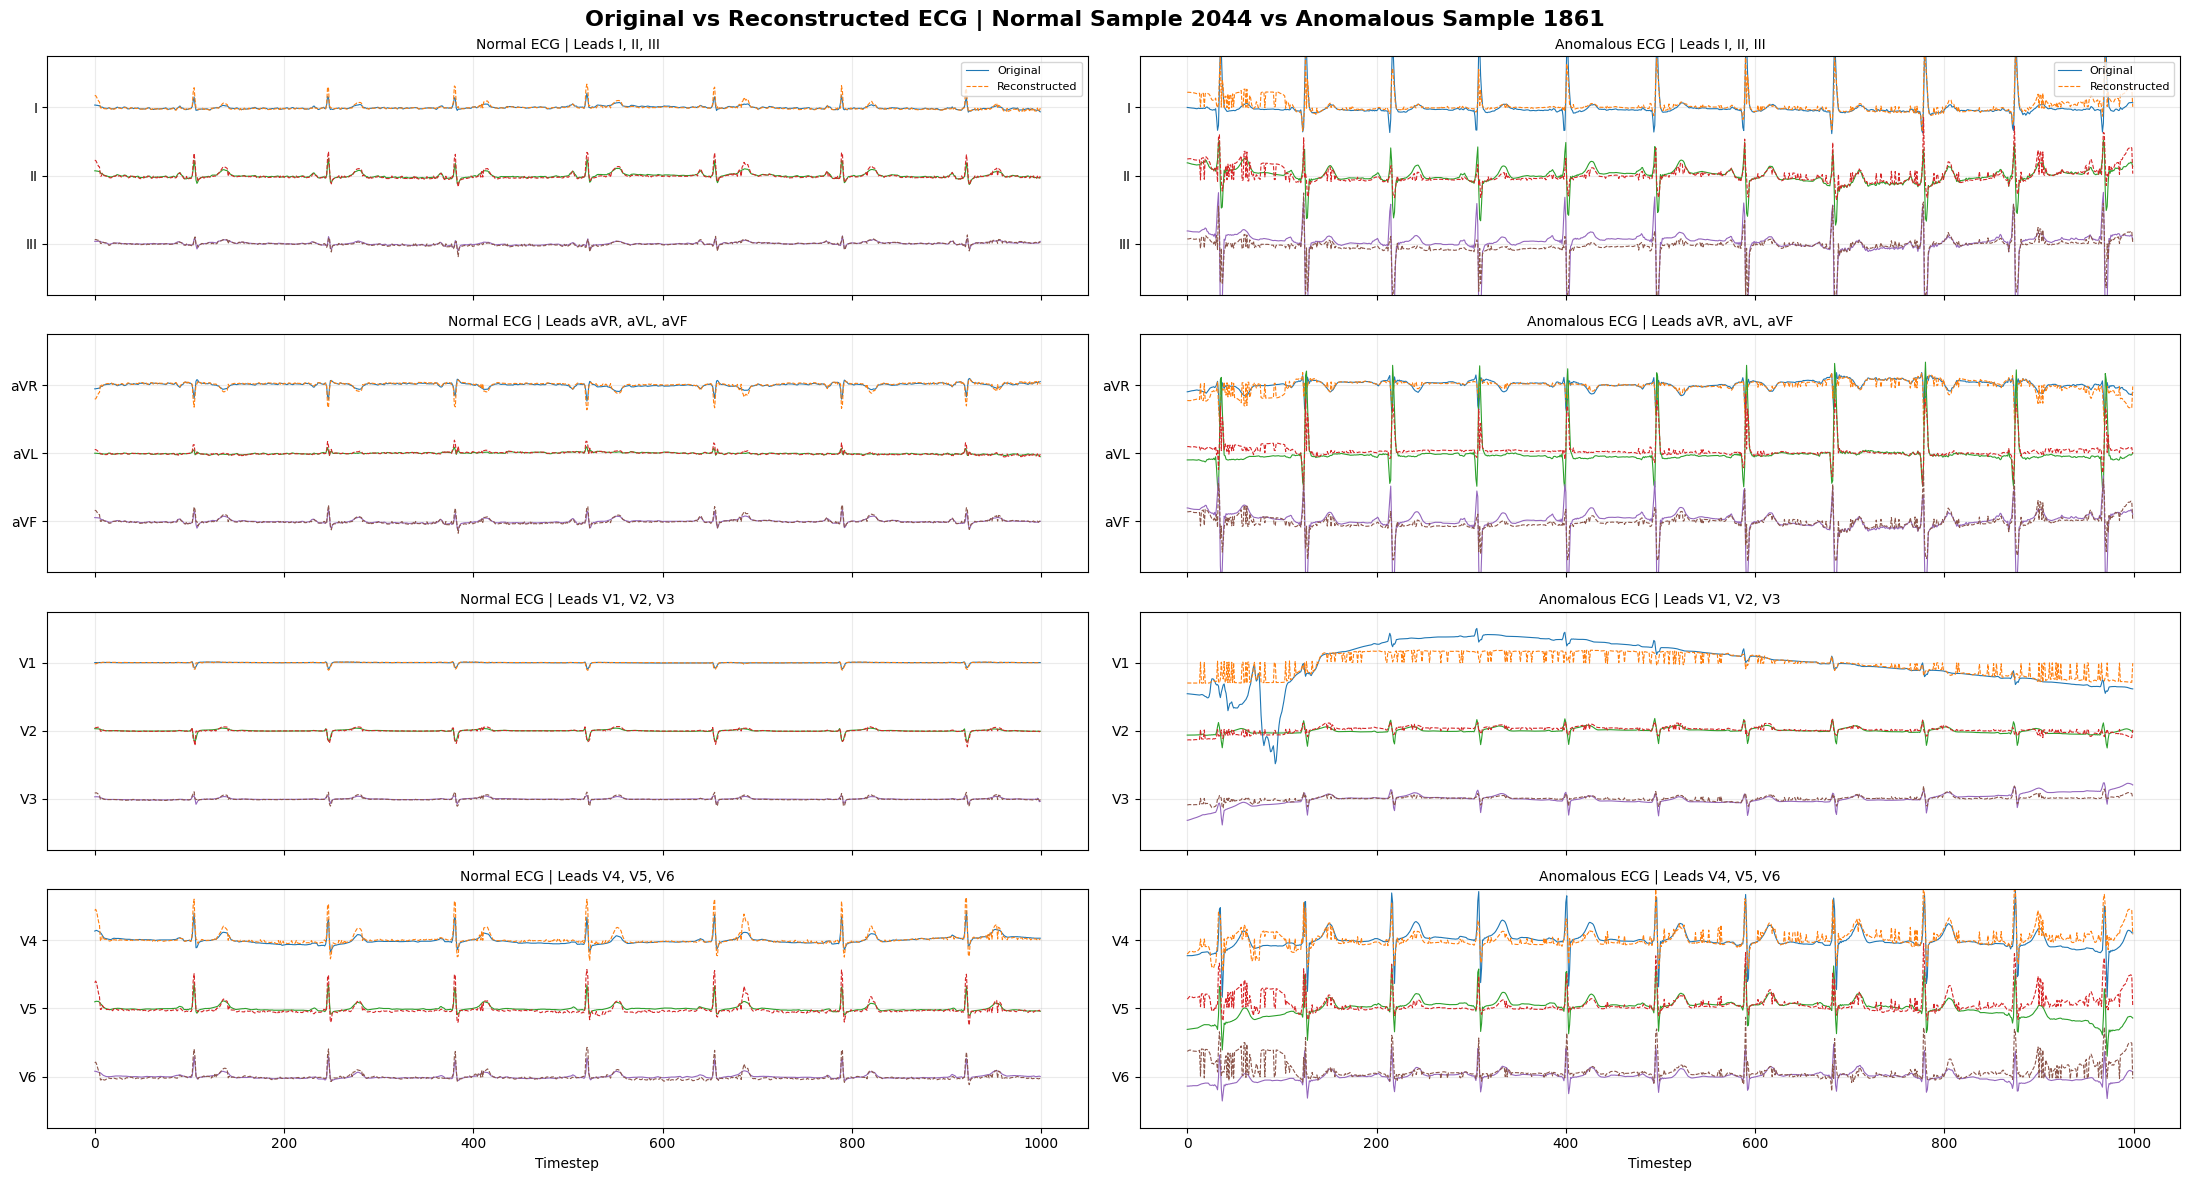

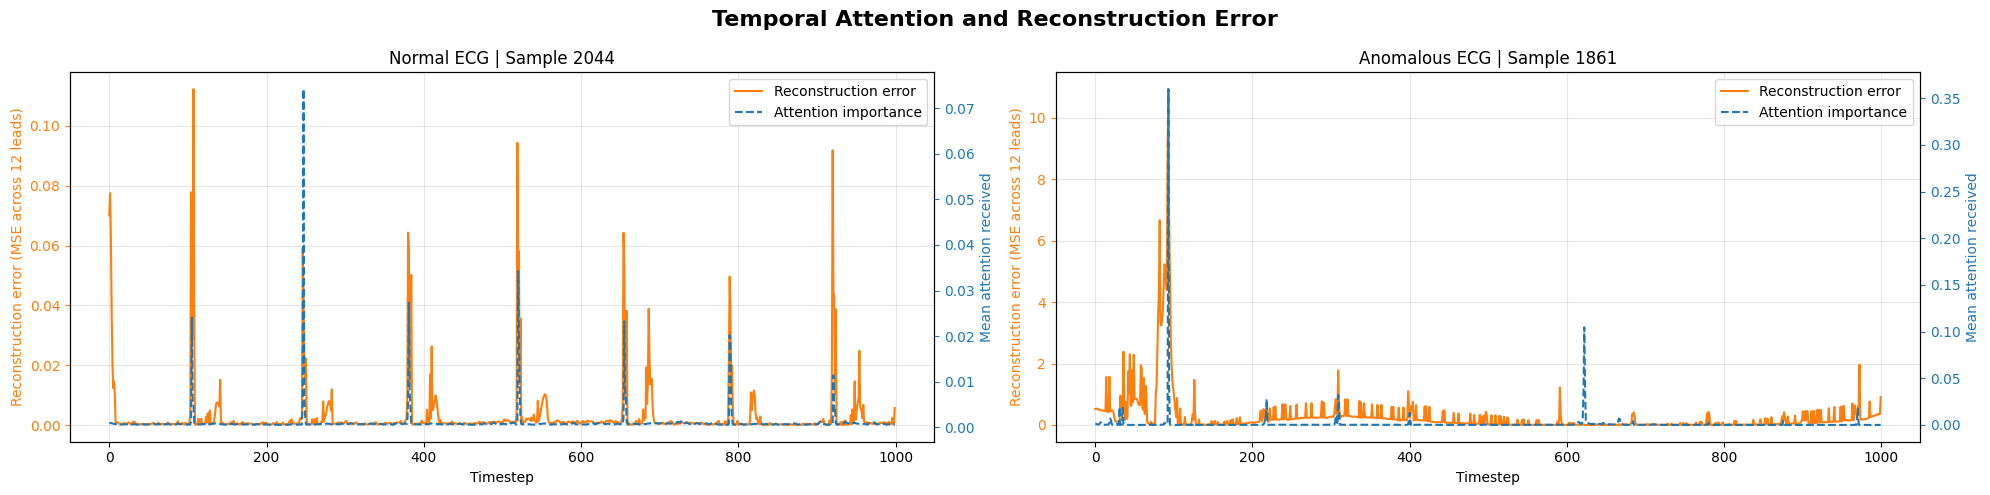

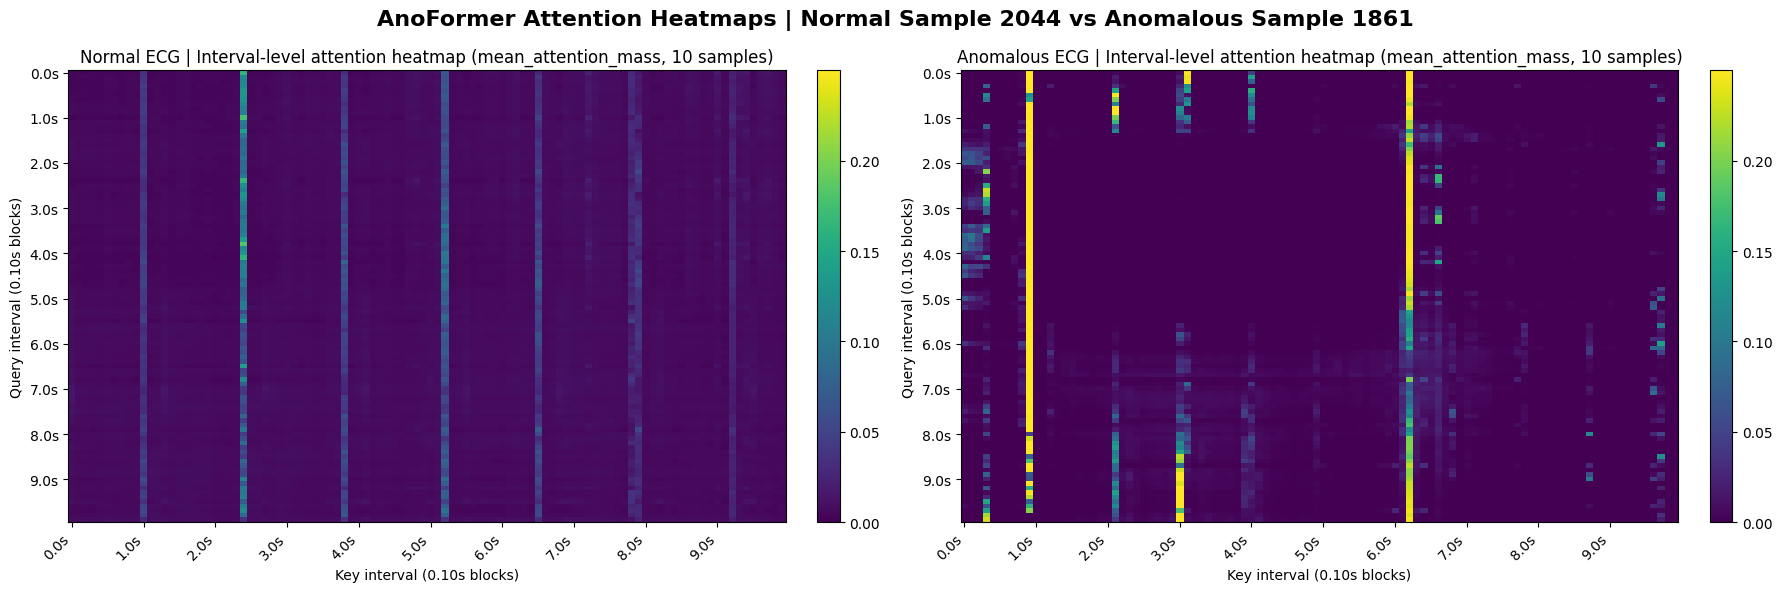

In [ ]:
# Attention-based Explainability: Normal vs Anomalous

import numpy as np

Explainer = AnoFormerExplainability(AnoFormer)


NormalECG, NormalLabel = test_dataset[NormalIndex]
AnomalousECG, AnomalousLabel = test_dataset[AnomalousIndex]

NormalECG = NormalECG.unsqueeze(0).to(AnoFormer.Device)
AnomalousECG = AnomalousECG.unsqueeze(0).to(AnoFormer.Device)

print("Normal index:", NormalIndex, "Label:", NormalLabel.item())
print("Anomalous index:", AnomalousIndex, "Label:", AnomalousLabel.item())

Explainer.CompareNormalAndAnomalousAttention(
    NormalWindow=NormalECG,
    AnomalousWindow=AnomalousECG,
    DatasetForInverseNorm=test_dataset,
    NormalIndex=NormalIndex,
    AnomalousIndex=AnomalousIndex,
    BlockIndex=0,
    HeadIndex=None,
    Percentile=99.0,
    UseIntervalHeatmap=True,
    BlockSize=10,
    Aggregation="mean_attention_mass",
    SamplingRate=100,
)

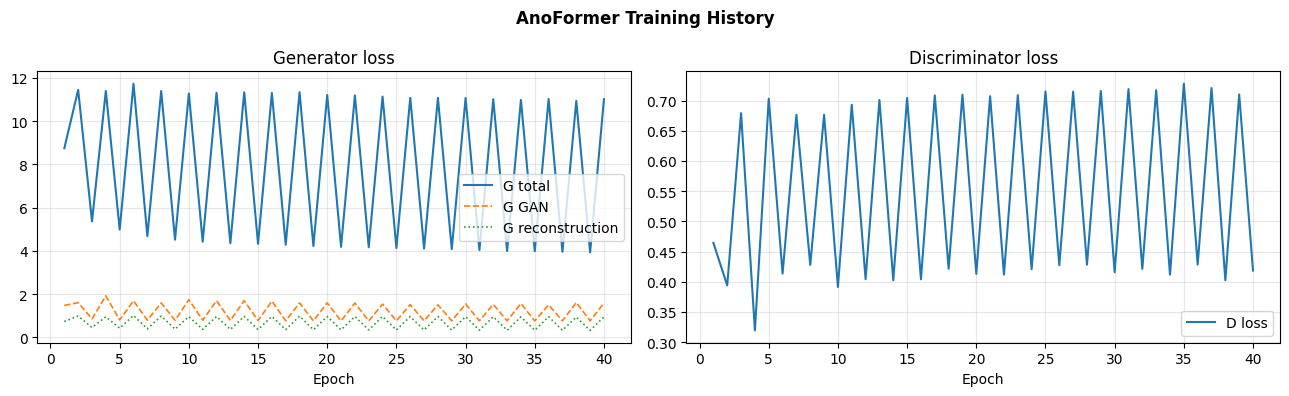

In [ ]:
# Show training loss

Explainer.ShowTrainingHistory()